# Beta Distribution

Companion notebook for the [beta distribution note](../../notes/random_variables_and_distributions/continuous/beta_distribution.md) and its [exercises](../../exercises/random_variables_and_distributions/beta_distribution.md).

$X\sim\text{Beta}(\alpha,\beta)$ lives on $[0,1]$:

$$f(x)=\frac{x^{\alpha-1}(1-x)^{\beta-1}}{B(\alpha,\beta)},\qquad E[X]=\frac{\alpha}{\alpha+\beta},\qquad \operatorname{Var}(X)=\frac{\alpha\beta}{(\alpha+\beta)^2(\alpha+\beta+1)}.$$

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

rng = np.random.default_rng(42)  # seeded for reproducible simulations

## Hand-rolled implementation

The PDF uses $B(\alpha,\beta)=\Gamma(\alpha)\Gamma(\beta)/\Gamma(\alpha+\beta)$. For integer shapes the CDF has a closed form: $F(x)=P(\text{Binomial}(\alpha+\beta-1,x)\ge\alpha)$.

In [2]:
class BetaDistribution:
    def __init__(self, alpha, beta_param):
        self.alpha = alpha
        self.beta = beta_param

    def pdf(self, x):
        x = np.asarray(x, dtype=float)
        norm = math.gamma(self.alpha) * math.gamma(self.beta) / math.gamma(self.alpha + self.beta)
        return x ** (self.alpha - 1) * (1 - x) ** (self.beta - 1) / norm

    def cdf(self, x):
        """Closed form for integer shapes: P(Binomial(a+b-1, x) >= a)."""
        x = np.asarray(x, dtype=float)
        n = self.alpha + self.beta - 1
        return sum(math.comb(n, j) * x**j * (1 - x) ** (n - j) for j in range(self.alpha, n + 1))

## Check against `scipy.stats`

In [3]:
a1, b1 = 2, 5
a2, b2 = 5, 2
x = np.linspace(0, 1, 1000)
d1, d2 = BetaDistribution(a1, b1), BetaDistribution(a2, b2)

pdf1, pdf2 = stats.beta.pdf(x, a1, b1), stats.beta.pdf(x, a2, b2)
cdf1, cdf2 = stats.beta.cdf(x, a1, b1), stats.beta.cdf(x, a2, b2)
print("PDF matches:", np.allclose(d1.pdf(x), pdf1), np.allclose(d2.pdf(x), pdf2))
print("CDF matches:", np.allclose(d1.cdf(x), cdf1), np.allclose(d2.cdf(x), cdf2))
print("Beta(2,5): mean", stats.beta.mean(a1, b1).round(4), " var", stats.beta.var(a1, b1).round(4))

PDF matches: True True
CDF matches: True True
Beta(2,5): mean 0.2857  var 0.0255


## Shape of the PDF and CDF

Beta(2, 5) is right-skewed (mean $0.286$) and Beta(5, 2) is its mirror image (mean $0.714$): swapping $\alpha,\beta$ reflects the density about $x=0.5$.

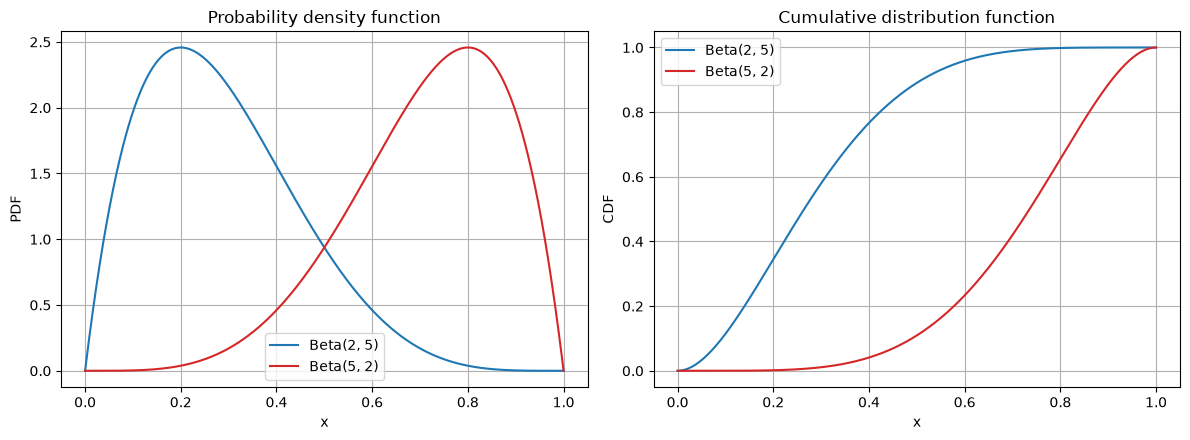

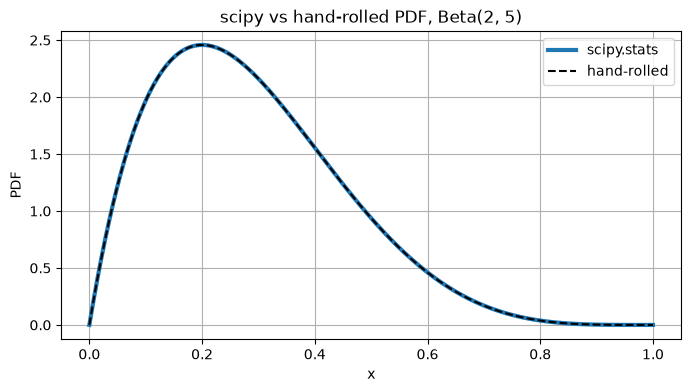

In [4]:
def plot_pdf_cdf(x, pdf1, cdf1, label1, pdf2, cdf2, label2):
    """PDF and CDF of two distributions side by side."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
    ax1.plot(x, pdf1, color="C0", label=label1)
    ax1.plot(x, pdf2, color="C3", label=label2)
    ax1.set(xlabel="x", ylabel="PDF", title="Probability density function")
    ax2.plot(x, cdf1, color="C0", label=label1)
    ax2.plot(x, cdf2, color="C3", label=label2)
    ax2.set(xlabel="x", ylabel="CDF", title="Cumulative distribution function")
    for ax in (ax1, ax2):
        ax.legend()
        ax.grid(True)
    plt.tight_layout()
    plt.show()


def plot_overlay(x, ref, custom, title):
    """Hand-rolled PDF (dashed) on top of the scipy.stats PDF (solid)."""
    plt.figure(figsize=(8, 4))
    plt.plot(x, ref, color="C0", linewidth=3, label="scipy.stats")
    plt.plot(x, custom, "k--", label="hand-rolled")
    plt.xlabel("x")
    plt.ylabel("PDF")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()


plot_pdf_cdf(x, pdf1, cdf1, f"Beta({a1}, {b1})", pdf2, cdf2, f"Beta({a2}, {b2})")
plot_overlay(x, pdf1, d1.pdf(x), "scipy vs hand-rolled PDF, Beta(2, 5)")

## Worked example: defect proportion and Bayesian updating

From the note: the defective proportion is Beta(2, 5). A Beta prior is conjugate to binomial data: after $s$ successes and $f$ failures the posterior is Beta$(\alpha+s,\beta+f)$.

E[X] = 0.2857, Var(X) = 0.0255, mode = 0.20


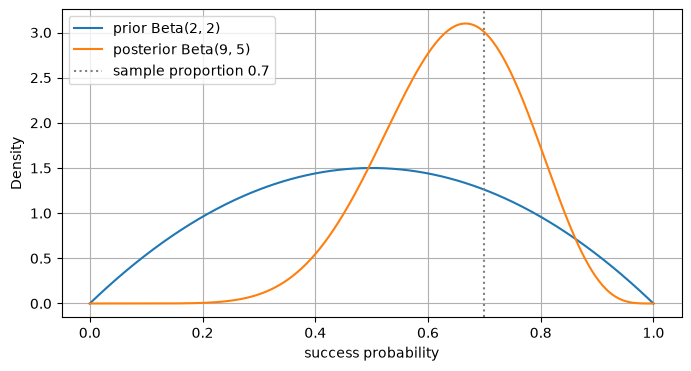

Posterior mean: 0.6429


In [5]:
m = stats.beta.mean(2, 5)
v = stats.beta.var(2, 5)
print(f"E[X] = {m:.4f}, Var(X) = {v:.4f}, mode = {(2 - 1) / (2 + 5 - 2):.2f}")

# Prior Beta(2, 2); observe 7 successes in 10 trials -> posterior Beta(9, 5)
prior, post = (2, 2), (2 + 7, 2 + 3)
t = np.linspace(0, 1, 500)
plt.figure(figsize=(8, 4))
plt.plot(t, stats.beta.pdf(t, *prior), label="prior Beta(2, 2)")
plt.plot(t, stats.beta.pdf(t, *post), label="posterior Beta(9, 5)")
plt.axvline(7 / 10, color="gray", linestyle=":", label="sample proportion 0.7")
plt.xlabel("success probability")
plt.ylabel("Density")
plt.legend()
plt.grid(True)
plt.show()
print("Posterior mean:", round(stats.beta.mean(*post), 4))

## Simulation versus theory

mean: sample 0.2854  theory 0.2857
var : sample 0.0255  theory 0.0255


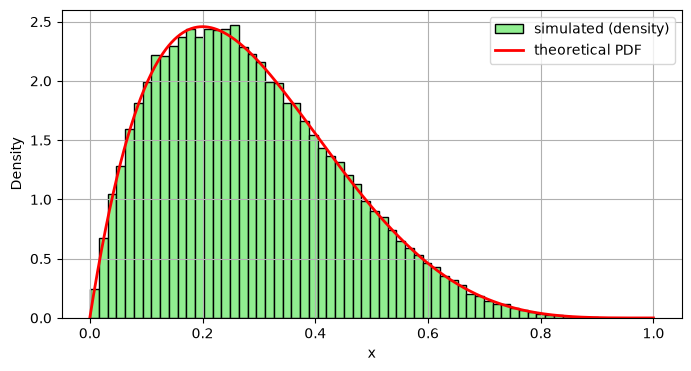

In [6]:
sample = rng.beta(a1, b1, size=100_000)
print(f"mean: sample {sample.mean():.4f}  theory {a1 / (a1 + b1):.4f}")
print(f"var : sample {sample.var():.4f}  theory {a1 * b1 / ((a1 + b1) ** 2 * (a1 + b1 + 1)):.4f}")

plt.figure(figsize=(8, 4))
plt.hist(sample, bins=60, density=True, color="lightgreen", edgecolor="black", label="simulated (density)")
plt.plot(x, stats.beta.pdf(x, a1, b1), "r-", linewidth=2, label="theoretical PDF")
plt.xlabel("x")
plt.ylabel("Density")
plt.legend()
plt.grid(True)
plt.show()

## Takeaways

* Beta is the natural model for proportions and probabilities on $[0,1]$.
* The mean $\alpha/(\alpha+\beta)$ and the concentration $\alpha+\beta$ together determine the shape.
* Conjugacy with the binomial makes updating a matter of adding counts.